# Quanto PM10 domani? Una regressione sui dati di ARPA Lombardia · soluzione
**Script intelligenti: sviluppare modelli di Machine Learning con il codice**

I dati: **open data di ARPA Lombardia** (dati.lombardia.it, licenza IODL 2.0). Il PM10 della centralina di
Voghera, via Pozzoni; pioggia e temperatura di Voghera, via Cambiaso; il vento di Cornale, a 9 km. Un giorno per riga,
dal 21 aprile al 18 novembre 2026.

La domanda: **quanto PM10 ci sarà domani?** È una regressione: la label è un numero, in µg/m³.

Oggi non scriviamo codice a mano: lo scrive **Gemini**, l'assistente di Colab. Il nostro lavoro è chiedere bene e
controllare il risultato.

| | |
|---|---|
| **1 · Chiedi chiaro** | che cosa vuoi, con quali dati, in che forma vuoi il risultato |
| **2 · Leggi** | il codice proposto, anche senza capirlo tutto: quali dati usa? che cosa calcola? |
| **3 · Esegui** | e guarda che cosa succede, errori compresi |
| **4 · Controlla** | il risultato torna con quello che sai? I numeri sono plausibili? |

> **Versione per il docente.** Ogni tappa ha il codice di una soluzione possibile, già eseguito. Gemini
> scriverà codice diverso, a volte con nomi diversi: va bene, conta che i risultati tornino.

## Come chiedere a Gemini
1. In una cella di codice vuota, cliccate su **genera** (oppure aprite il pannello di Gemini, in alto a destra).
2. Scrivete la richiesta in italiano: potete copiare il prompt di esempio.
3. Leggete il codice proposto prima di accettarlo.
4. Eseguitelo con ▶ e guardate il risultato.

*Se Gemini non è disponibile:* usate ChatGPT o Claude in un'altra scheda e incollate qui il codice.

## Preparazione
Eseguite questa cella con ▶: scarica i dati. Se il download non funziona, caricate i file a mano dal pannello **File** (l'icona a forma di cartella a sinistra).

In [1]:
# Scarica i file dei dati nella cartella di lavoro di Colab.
import os
import urllib.request

if not os.path.exists("pm10_voghera.csv"):
    urllib.request.urlretrieve("https://raw.githubusercontent.com/matteolimoncini/script-intelligenti/main/incontro-3/dati/pm10_voghera.csv", "pm10_voghera.csv")
print("File pronti:", "pm10_voghera.csv")

File pronti: pm10_voghera.csv


## Tappa 1 · Guardare i dati
Ogni riga è un giorno a Voghera. **pm10** è la label: le polveri sottili di quel giorno, in microgrammi per
metro cubo (µg/m³). Le feature: **pm10_ieri**, **pioggia** (mm in tutto il giorno), **temperatura** (media, °C),
**vento** (media, m/s).

**Prompt di esempio:**

> Carica pm10_voghera.csv con pandas. Fai il grafico del pm10 nel tempo (la colonna data sull'asse orizzontale) e
> dimmi la media del pm10 per ogni mese.

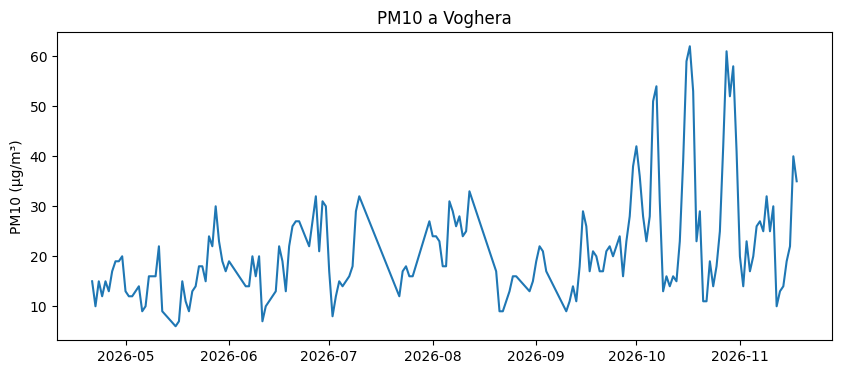

mese
4     15.5
5     15.1
6     19.8
7     17.6
8     20.1
9     20.1
10    32.5
11    22.9
Name: pm10, dtype: float64

In [2]:
import pandas as pd
import matplotlib.pyplot as plt

dati = pd.read_csv("pm10_voghera.csv", parse_dates=["data"])
plt.figure(figsize=(10, 4))
plt.plot(dati["data"], dati["pm10"])
plt.ylabel("PM10 (µg/m³)")
plt.title("PM10 a Voghera")
plt.show()
dati.groupby("mese")["pm10"].mean().round(1)

**Domande**
- In quali mesi il PM10 è più alto? Perché, secondo voi?
- Un giorno con PM10 alto è di solito seguito da un altro giorno alto?

**Che cosa si deve vedere:** 173 giorni, da aprile a novembre 2026. Il PM10 sta intorno a 15–20 µg/m³ in primavera ed estate e
sale in ottobre (circa 32): in autunno l'aria ristagna e si accendono i riscaldamenti.

## Tappa 2 · Due basi da battere
Prima di un modello, due modi semplici di predire: **sempre la media** e **domani come oggi** (il PM10 di
ieri). Dividiamo nel tempo, senza mescolare: i primi giorni per imparare, gli ultimi per la prova.

**Prompt di esempio:**

> Dividi i dati in addestramento e test senza mescolarli: il primo 80% dei giorni per l'addestramento, l'ultimo 20%
> per il test (train_test_split con shuffle=False). Sul test calcola il MAE di chi prevede sempre la media del pm10
> dell'addestramento e il MAE di chi prevede che il pm10 sia uguale a pm10_ieri.

In [3]:
import numpy as np
from sklearn.metrics import mean_absolute_error
from sklearn.model_selection import train_test_split

train, test = train_test_split(dati, test_size=0.2, shuffle=False)
print("Addestramento:", train["data"].min().date(), "→", train["data"].max().date(), " test:",
      test["data"].min().date(), "→", test["data"].max().date())
print("Sempre la media, MAE:   ", round(mean_absolute_error(test["pm10"], np.full(len(test), train["pm10"].mean())), 1))
print("Domani come oggi, MAE:  ", round(mean_absolute_error(test["pm10"], test["pm10_ieri"]), 1))

Addestramento: 2026-04-21 → 2026-10-14  test: 2026-10-15 → 2026-11-18
Sempre la media, MAE:    13.1
Domani come oggi, MAE:   9.2


**Domande**
- Quale delle due basi sbaglia meno? Perché?
- Perché qui non si mescolano i giorni prima di dividerli?

**Che cosa si deve vedere:** il test va dal 15 ottobre al 18 novembre. Sempre la media sbaglia di circa 13 µg/m³, domani come oggi
di circa 9: il PM10 cambia lentamente, quindi ieri è già una buona previsione.

## Tappa 3 · Una regressione con più variabili
**Prompt di esempio:**

> Addestra una regressione lineare che predice pm10 da pm10_ieri, pioggia, vento e temperatura, con la stessa
> divisione. Dimmi il MAE sul test e i coefficienti. Poi rifai tutto usando solo pioggia, vento e temperatura.

In [4]:
from sklearn.linear_model import LinearRegression

for feature in (["pm10_ieri", "pioggia", "vento", "temperatura"], ["pioggia", "vento", "temperatura"]):
    modello = LinearRegression().fit(train[feature], train["pm10"])
    mae = mean_absolute_error(test["pm10"], modello.predict(test[feature]))
    print(feature, " MAE:", round(mae, 1))
    print("   coefficienti:", {f: float(c) for f, c in zip(feature, modello.coef_.round(2))})

['pm10_ieri', 'pioggia', 'vento', 'temperatura']  MAE: 9.1
   coefficienti: {'pm10_ieri': 0.72, 'pioggia': -0.21, 'vento': -1.42, 'temperatura': 0.16}
['pioggia', 'vento', 'temperatura']  MAE: 15.3
   coefficienti: {'pioggia': -0.1, 'vento': -1.27, 'temperatura': 0.37}


**Domande**
- La regressione batte le due basi? Di quanto?
- Senza il PM10 di ieri, il meteo da solo fa meglio o peggio della media? Che cosa è cambiato in autunno rispetto ai
  mesi da cui il modello ha imparato?
- Il coefficiente del vento è negativo: che cosa vuol dire?

**Che cosa si deve vedere:** con tutte le variabili MAE circa 9: poco meglio della media, non meglio di «domani come oggi». Con il
solo meteo circa 15, peggio della media: il modello ha imparato in primavera ed estate e il test è in autunno, quando
il PM10 si comporta diversamente (è il drift dell'incontro 4). Più vento, meno PM10: il vento disperde le polveri.

## Tappa 4 · E se mescoliamo i giorni?
**Prompt di esempio:**

> Rifai la regressione con tutte le variabili, ma dividendo a caso (train_test_split con random_state=42, senza
> shuffle=False). Confronta il MAE con quello di prima.

In [5]:
a_caso_train, a_caso_test = train_test_split(dati, test_size=0.2, random_state=42)
feature = ["pm10_ieri", "pioggia", "vento", "temperatura"]
modello = LinearRegression().fit(a_caso_train[feature], a_caso_train["pm10"])
print("Divisione a caso, MAE:", round(mean_absolute_error(a_caso_test["pm10"], modello.predict(a_caso_test[feature])), 1))

Divisione a caso, MAE: 4.5


**Domande**
- Il modello sembra molto migliore. Lo è davvero?
- Che cosa ha visto il modello durante l'addestramento che, nella realtà, non potrebbe vedere?

**Che cosa si deve vedere:** circa 4,5: sembra bravissimo, ma ha imparato da giorni di ottobre e novembre vicinissimi a quelli del
test. Nella realtà il futuro non si conosce: per i dati nel tempo si divide nel tempo (è un caso di leakage,
come nell'incontro 2).

## Per finire
Prima di fidarsi di un modello si confronta con una base semplice: qui «domani come oggi» è difficile da battere. Con
i dati nel tempo si divide nel tempo, se no il modello vede il futuro. E quando cambia la stagione cambiano anche i
dati: il modello va controllato e riaddestrato (incontro 4). **In classe:** gli studenti possono scaricare i dati
della centralina più vicina alla scuola dal sito di ARPA Lombardia e ripetere le quattro tappe.